# 接触对象：内部接触、Rg与外部连接的联合分析

读取按simulation_id、source_frame、chain_id配对的结果，不重算接触或Rg。
浅点为同帧同链，菱形为帧内均值；条件差异与单一模拟内部的关系需分别解释，相关不等于竞争或因果。
中心链可逐帧换身份，不能把它当作固定链的连续变化。内部每残基接触数=2E/N，外部=Ca/N。

在首个代码单元选择OBJECT：central_chain为每帧中心链，dense_chains为全部浓相链。


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "simulations.yaml").is_file())
sys.path.insert(0, str(ROOT))
from common import inputs
from common import results as files

SELECTED = None
OBJECT = "central_chain"  # central_chain / dense_chains
RESULTS_ROOT = ROOT / "03_results"
SIMULATIONS = inputs.select_simulations(ROOT / "simulations.yaml", SELECTED)
RESULTS = {s["id"]: files.completed(RESULTS_ROOT / s["id"] / "02_contacts/03_joint" / OBJECT) for s in SIMULATIONS}
SOURCES = {name: files.read_json(path / "metadata.json") for name, path in RESULTS.items()}
COLORS = {name: plt.get_cmap("tab10")(i % 10) for i, name in enumerate(RESULTS)}
FIGURES = ROOT / "05_plot/02_contacts/03_joint/figures" / OBJECT
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "legend.frameon": False,
    }
)


def export(fig, name):
    for key, path in RESULTS.items():
        files.completed(path)
        if files.read_json(path / "metadata.json") != SOURCES[key]:
            raise ValueError("Results changed; restart notebook")
    for ext in ("png", "pdf", "svg"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    files.write_json(FIGURES / f"{name}.sources.json", SOURCES)


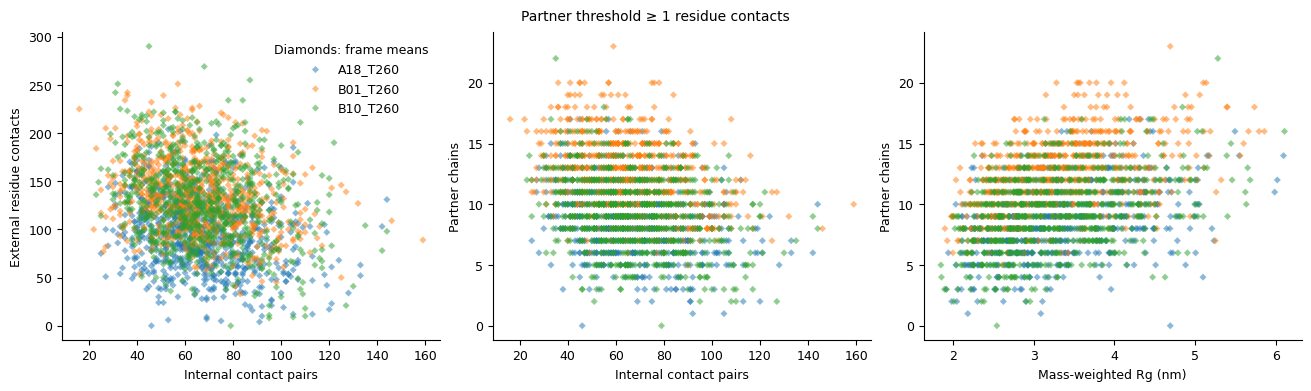

,simulation_id,threshold,contact_count_mean_frames,contact_count_std_frames,contact_count_count_frames,rg_nm_mean_frames,rg_nm_std_frames,rg_nm_count_frames,total_contacts_mean_frames,total_contacts_std_frames,...,total_contacts_sem_blocks,partner_count_std_blocks,partner_count_count_blocks,partner_count_sem_blocks,intra_contacts_per_residue_std_blocks,intra_contacts_per_residue_count_blocks,intra_contacts_per_residue_sem_blocks,inter_contacts_per_residue_std_blocks,inter_contacts_per_residue_count_blocks,inter_contacts_per_residue_sem_blocks
0,A18_T260,1,66.864000,19.789686,750,3.300322,0.725788,750,94.702667,37.945761,...,2.468139,0.871251,15,0.224956,0.047981,15,0.012389,0.074101,15,0.019133
1,A18_T260,5,66.864000,19.789686,750,3.300322,0.725788,750,94.702667,37.945761,...,2.468139,0.651059,15,0.168103,0.047981,15,0.012389,0.074101,15,0.019133
2,A18_T260,10,66.864000,19.789686,750,3.300322,0.725788,750,94.702667,37.945761,...,2.468139,0.387534,15,0.100061,0.047981,15,0.012389,0.074101,15,0.019133
3,B01_T260,1,65.906667,20.048721,750,3.309412,0.738130,750,135.053333,37.434301,...,1.417971,0.463416,15,0.119653,0.035760,15,0.009233,0.042572,15,0.010992
4,B01_T260,5,65.906667,20.048721,750,3.309412,0.738130,750,135.053333,37.434301,...,1.417971,0.428383,15,0.110608,0.035760,15,0.009233,0.042572,15,0.010992
5,B01_T260,10,65.906667,20.048721,750,3.309412,0.738130,750,135.053333,37.434301,...,1.417971,0.290681,15,0.075053,0.035760,15,0.009233,0.042572,15,0.010992
6,B10_T260,1,67.481333,20.322409,750,3.257619,0.747100,750,127.592000,44.035839,...,3.461802,1.098229,15,0.283561,0.051490,15,0.013295,0.103934,15,0.026836
7,B10_T260,5,67.481333,20.322409,750,3.257619,0.747100,750,127.592000,44.035839,...,3.461802,0.737078,15,0.190313,0.051490,15,0.013295,0.103934,15,0.026836
8,B10_T260,10,67.481333,20.322409,750,3.257619,0.747100,750,127.592000,44.035839,...,3.461802,0.592727,15,0.153042,0.051490,15,0.013295,0.103934,15,0.026836


In [2]:
PAIRED = {name: pd.read_csv(path / "paired_chain_frames.csv.gz") for name, path in RESULTS.items()}
FRAME = {name: pd.read_csv(path / "frame_means.csv") for name, path in RESULTS.items()}
shared = set.intersection(*(set(data.threshold.unique()) for data in FRAME.values()))
PRIMARY_THRESHOLD = min(shared)
comparisons = [
    ("contact_count", "total_contacts", "Internal contact pairs", "External residue contacts"),
    ("contact_count", "partner_count", "Internal contact pairs", "Partner chains"),
    ("rg_nm", "partner_count", "Mass-weighted Rg (nm)", "Partner chains"),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, (x, y, xlabel, ylabel) in zip(axes, comparisons):
    for name in RESULTS:
        data = PAIRED[name]
        data = data[data.threshold.eq(PRIMARY_THRESHOLD)]
        frame = FRAME[name]
        frame = frame[frame.threshold.eq(PRIMARY_THRESHOLD)]
        ax.scatter(
            data[x],
            data[y],
            s=5,
            alpha=0.04,
            color=COLORS[name],
            edgecolors="none",
            rasterized=True,
        )
        ax.scatter(
            frame[x],
            frame[y],
            s=13,
            alpha=0.5,
            color=COLORS[name],
            marker="D",
            label=name,
            edgecolors="none",
        )
    ax.set(xlabel=xlabel, ylabel=ylabel)
axes[0].legend(title="Diamonds: frame means")
fig.suptitle(f"Partner threshold ≥ {PRIMARY_THRESHOLD} residue contacts", fontsize=10)
export(fig, "intra_inter_rg_relationships")
plt.show()
display(
    pd.concat([pd.read_csv(path / "summary.csv") for path in RESULTS.values()], ignore_index=True)
)
